# 04 - Exploratory Data Analysis (EDA)

**Goal:** understand the problem and the clean data **visually**, before modeling.

- **Input:** `CSE_CIC_IDS2018_clean.parquet` (notebook 03)
- Nothing is modified here, only statistics and plots.

## 0. Problem analysis

**Context.** A bank connects its headquarters, branches and internal services. Its network carries
confidential data and must stay available. Attacks can cause **service outages** (DoS/DDoS),
**stolen credentials** (brute force on SSH/FTP), **data theft** (web attacks, infiltration) or
**compromised machines** controlled remotely (botnet).

**AI problem.** **Multi-class classification of network flows**: from the statistics of one flow (one connection
between two machines), predict whether it is `Benign` or **which type of attack** it is. Knowing the type matters,
because the response differs (rate limiting for a DDoS, account lockout for brute force, isolating a machine for an
infiltration).

**Data.** Each row is a flow described by numeric features extracted by CICFlowMeter: duration, packet counts,
byte counts, packet sizes, inter-arrival times (IAT), TCP flags, rates, destination port and protocol.

| Family | Attacks | Effect on a bank |
|---|---|---|
| DoS | Hulk, GoldenEye, Slowloris | Web services unavailable |
| DDoS | LOIC-HTTP, LOIC-UDP, HOIC | Massive outage from many sources |
| Brute force | SSH (FTP if kept after cleaning) | Stolen credentials |
| Web attacks | Brute Force -Web, -XSS, SQL Injection (merged) | Data theft, session hijacking |
| Botnet | Bot | Machine controlled remotely |
| Infiltration | Infilteration | Attacker already inside the network |

**Expected results.** A high **detection rate** with few **false alarms**. Because classes are imbalanced,
**accuracy is misleading**: the main metric will be **macro-F1**.

In [2]:
# Imports
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# Mount Drive
drive.mount("/content/drive")

# Paths
BASE = Path("/content/drive/MyDrive/Projects/CSE-CIC-IDS2018")
DATA_DIR = BASE / "data" / "processed"
FIG_DIR = BASE / "figures"
FIG_DIR.mkdir(exist_ok=True)
SEED = 42
pd.set_option("display.max_columns", 100)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load the clean data

In [3]:
df = pd.read_parquet(DATA_DIR / "CSE_CIC_IDS2018_clean.parquet")
feature_cols = [c for c in df.columns if c != "Label"]

print("Shape:", df.shape)
print("Features:", len(feature_cols))

Shape: (2966102, 71)
Features: 70


### Attack families
Group the classes into families, for some of the plots.

In [4]:
def family(label):
    if label == "Benign":
        return "Benign"
    if "DDOS" in label.upper():
        return "DDoS"
    if "DoS" in label:
        return "DoS"
    if "Brute" in label:
        return "Brute force"
    if label == "Web-Attack":
        return "Web attack"
    if label == "Bot":
        return "Botnet"
    if label == "Infilteration":
        return "Infiltration"
    return "Other"

df["Family"] = df["Label"].map(family)
df["Type"] = np.where(df["Label"] == "Benign", "Benign", "Attack")
df.groupby("Family")["Label"].unique()

,Label
Family,
Benign,[Benign]
Botnet,[Bot]
Brute force,[SSH-Bruteforce]
DDoS,"[DDoS attacks-LOIC-HTTP, DDOS attack-LOIC-UDP,..."
DoS,"[DoS attacks-Hulk, DoS attacks-GoldenEye, DoS ..."
Infiltration,[Infilteration]
Web attack,[Web-Attack]


### Plot sample
Some plots are slow on millions of rows, so they use a sample of **at most 5,000 rows per class**
(small classes are kept entirely).

In [5]:
plot_df = df.sample(frac=1, random_state=SEED).groupby("Label").head(5000)
print("Plot sample:", plot_df.shape)

Plot sample: (47581, 73)


## 2. Class distribution

In [6]:
counts = df["Label"].value_counts()
pd.DataFrame({"count": counts, "%": (100 * counts / counts.sum()).round(2)})

,count,%
Label,,
Benign,1643296,55.40
DDoS attacks-LOIC-HTTP,575012,19.39
DDOS attack-HOIC,198861,6.70
DoS attacks-Hulk,145199,4.90
Bot,144535,4.87
Infilteration,111473,3.76
SSH-Bruteforce,94041,3.17
DoS attacks-GoldenEye,41392,1.40
DoS attacks-Slowloris,9712,0.33


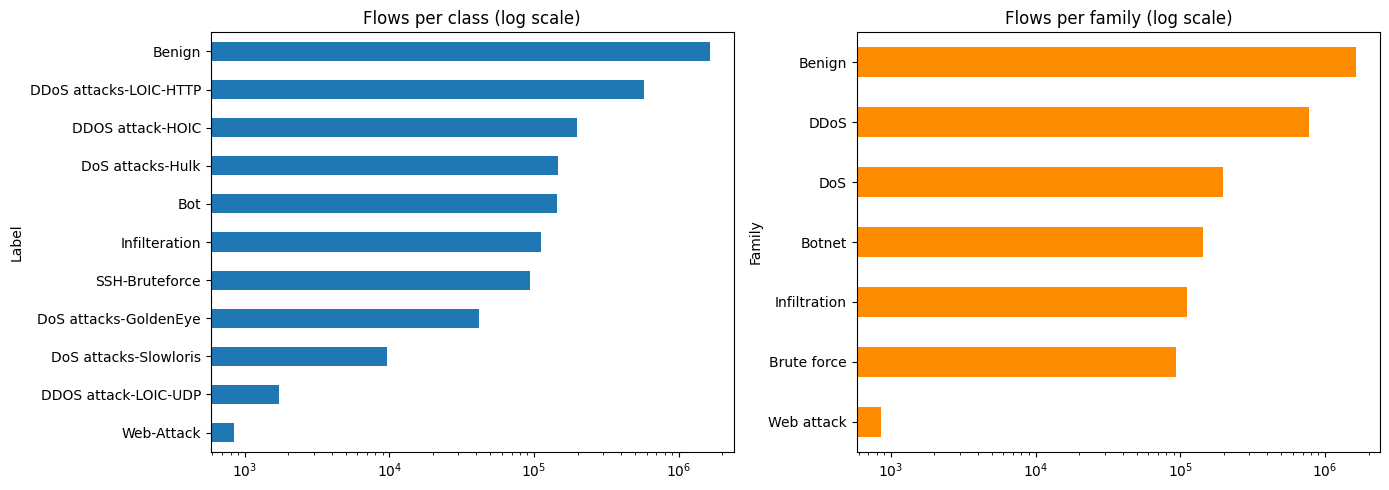

Imbalance ratio (largest / smallest class): 1,931 : 1


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

counts.sort_values().plot(kind="barh", logx=True, ax=axes[0])
axes[0].set_title("Flows per class (log scale)")

df["Family"].value_counts().sort_values().plot(kind="barh", logx=True, ax=axes[1], color="darkorange")
axes[1].set_title("Flows per family (log scale)")

plt.tight_layout()
plt.savefig(FIG_DIR / "04_class_distribution.png", dpi=150)
plt.show()

print(f"Imbalance ratio (largest / smallest class): {counts.max() / counts.min():,.0f} : 1")

## 3. Feature distributions: Benign vs Attack
The features are very **skewed** (most flows are small, a few are huge), so the x-axis uses `log1p(x)` = log(1 + x).

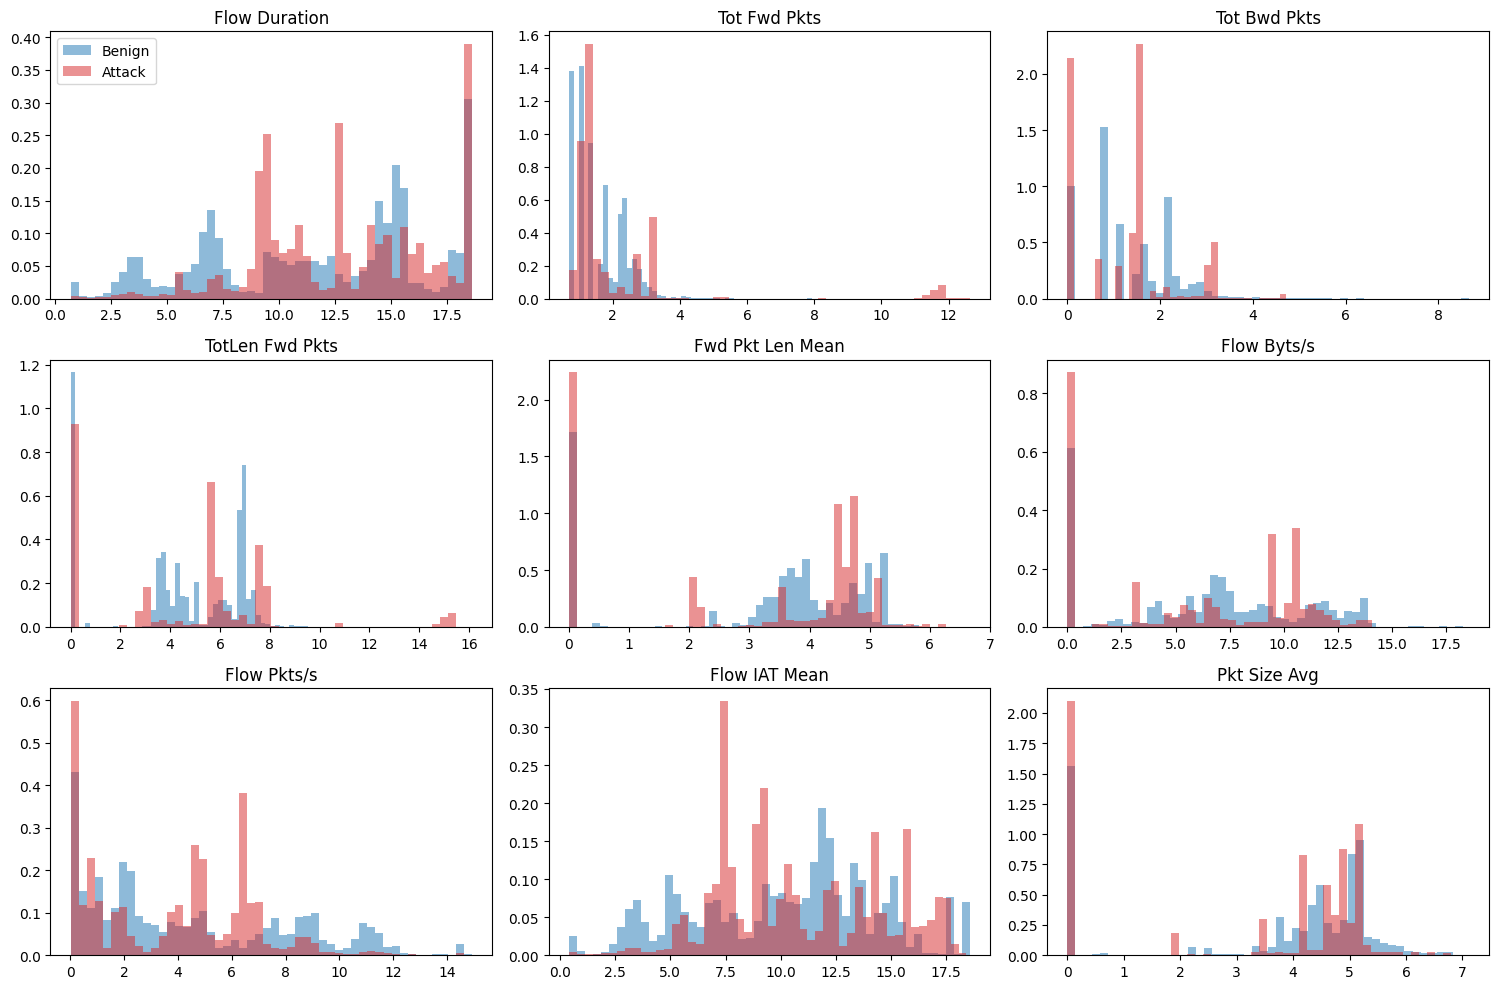

In [8]:
KEY = ["Flow Duration", "Tot Fwd Pkts", "Tot Bwd Pkts", "TotLen Fwd Pkts",
       "Fwd Pkt Len Mean", "Flow Byts/s", "Flow Pkts/s", "Flow IAT Mean", "Pkt Size Avg"]

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.ravel(), KEY):
    for t, color in [("Benign", "tab:blue"), ("Attack", "tab:red")]:
        values = np.log1p(plot_df.loc[plot_df["Type"] == t, col].clip(lower=0))
        ax.hist(values, bins=50, alpha=0.5, density=True, label=t, color=color)
    ax.set_title(col)
axes[0, 0].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "04_distributions.png", dpi=150)
plt.show()

In [9]:
skew = df[feature_cols].skew().abs().sort_values(ascending=False)
print(f"Features with |skewness| > 10: {(skew > 10).sum()} / {len(skew)}")
skew.head(10).round(1)

Features with |skewness| > 10: 29 / 70


,0
Pkt Len Var,275.700012
Bwd Header Len,254.500000
Tot Bwd Pkts,254.399994
Subflow Bwd Pkts,254.399994
TotLen Bwd Pkts,227.100006
Subflow Bwd Byts,227.000000
Flow Byts/s,131.699997
Down/Up Ratio,129.199997
CWE Flag Count,51.500000
Fwd URG Flags,51.500000


## 4. Key features per class
Each attack has its own "signature". The boxplots use `log1p` and hide extreme outliers.

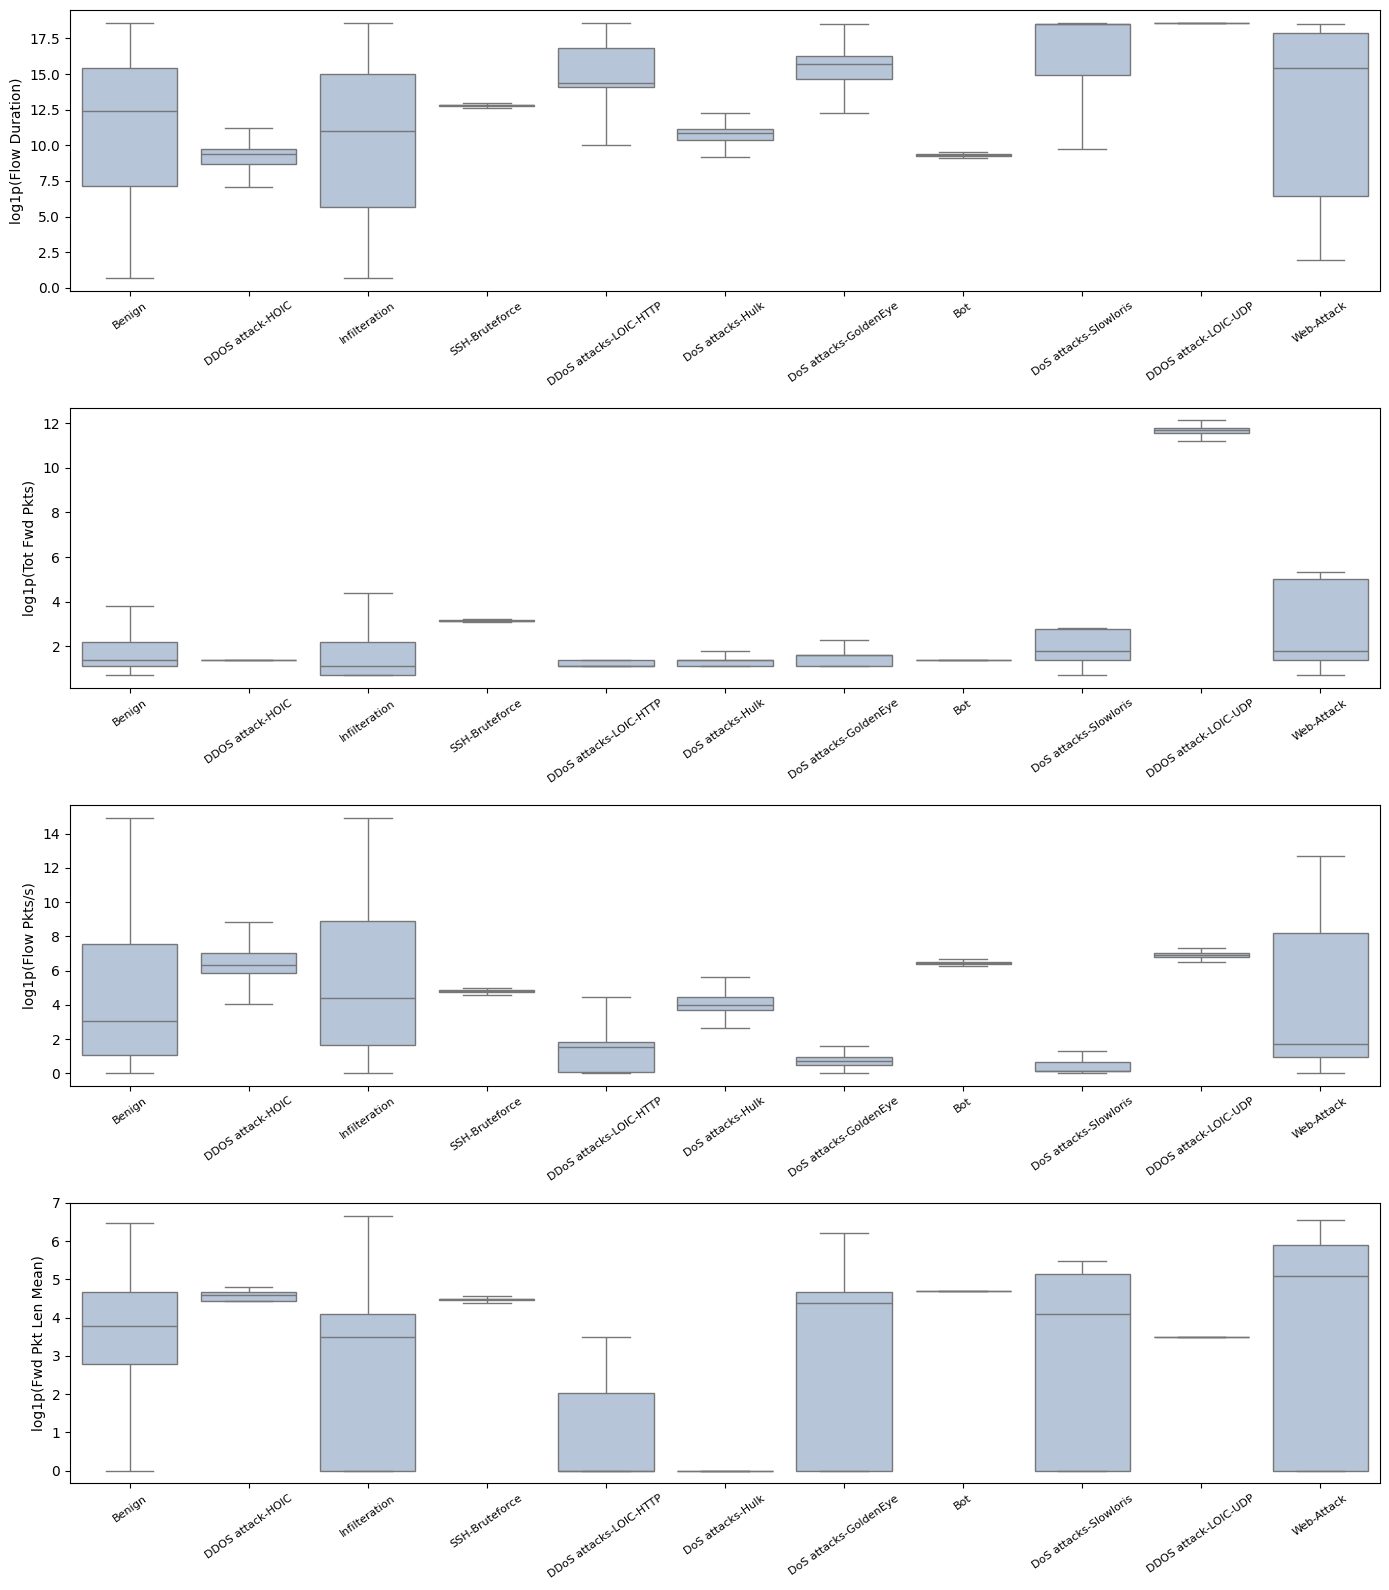

In [10]:
BOX = ["Flow Duration", "Tot Fwd Pkts", "Flow Pkts/s", "Fwd Pkt Len Mean"]
order = plot_df["Label"].value_counts().index

fig, axes = plt.subplots(len(BOX), 1, figsize=(14, 4 * len(BOX)))
for ax, col in zip(axes, BOX):
    data = plot_df[["Label", col]].copy()
    data[col] = np.log1p(data[col].clip(lower=0))
    sns.boxplot(data=data, x="Label", y=col, order=order, ax=ax, showfliers=False, color="lightsteelblue")
    ax.set_ylabel(f"log1p({col})")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35, labelsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_boxplots.png", dpi=150)
plt.show()

In [11]:
# Median of the key features per class
df.groupby("Label")[KEY].median().round(1)

,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,Fwd Pkt Len Mean,Flow Byts/s,Flow Pkts/s,Flow IAT Mean,Pkt Size Avg
Label,,,,,,,,,
Benign,267558.0,3.0,2.0,90.0,42.000000,829.1,19.600000,65164.5,89.000000
Bot,10909.0,3.0,4.0,326.0,108.699997,41636.2,642.200012,1816.5,65.000000
DDOS attack-HOIC,11702.0,3.0,4.0,291.0,97.000000,95125.8,555.599976,2125.3,175.100006
DDOS attack-LOIC-UDP,119777312.0,119758.5,0.0,3832272.0,32.000000,32523.7,1016.400024,983.9,32.000000
DDoS attacks-LOIC-HTTP,1746209.5,3.0,4.0,20.0,6.700000,523.4,3.800000,306754.1,140.600006
DoS attacks-GoldenEye,6771503.0,4.0,3.0,353.0,80.599998,122.5,1.000000,1619063.3,146.399994
DoS attacks-Hulk,50949.0,3.0,0.0,0.0,0.000000,0.0,53.099998,30503.0,0.000000
DoS attacks-Slowloris,106398364.0,5.0,2.0,246.0,76.699997,22.0,0.200000,6344713.0,127.000000
Infilteration,54810.0,2.0,1.0,42.0,31.000000,188.5,76.900002,20212.0,57.500000


## 5. Correlations between features
Many features are computed from each other (e.g. mean / max / total of the same packets), so strong
correlations are expected. Highly correlated features are redundant.

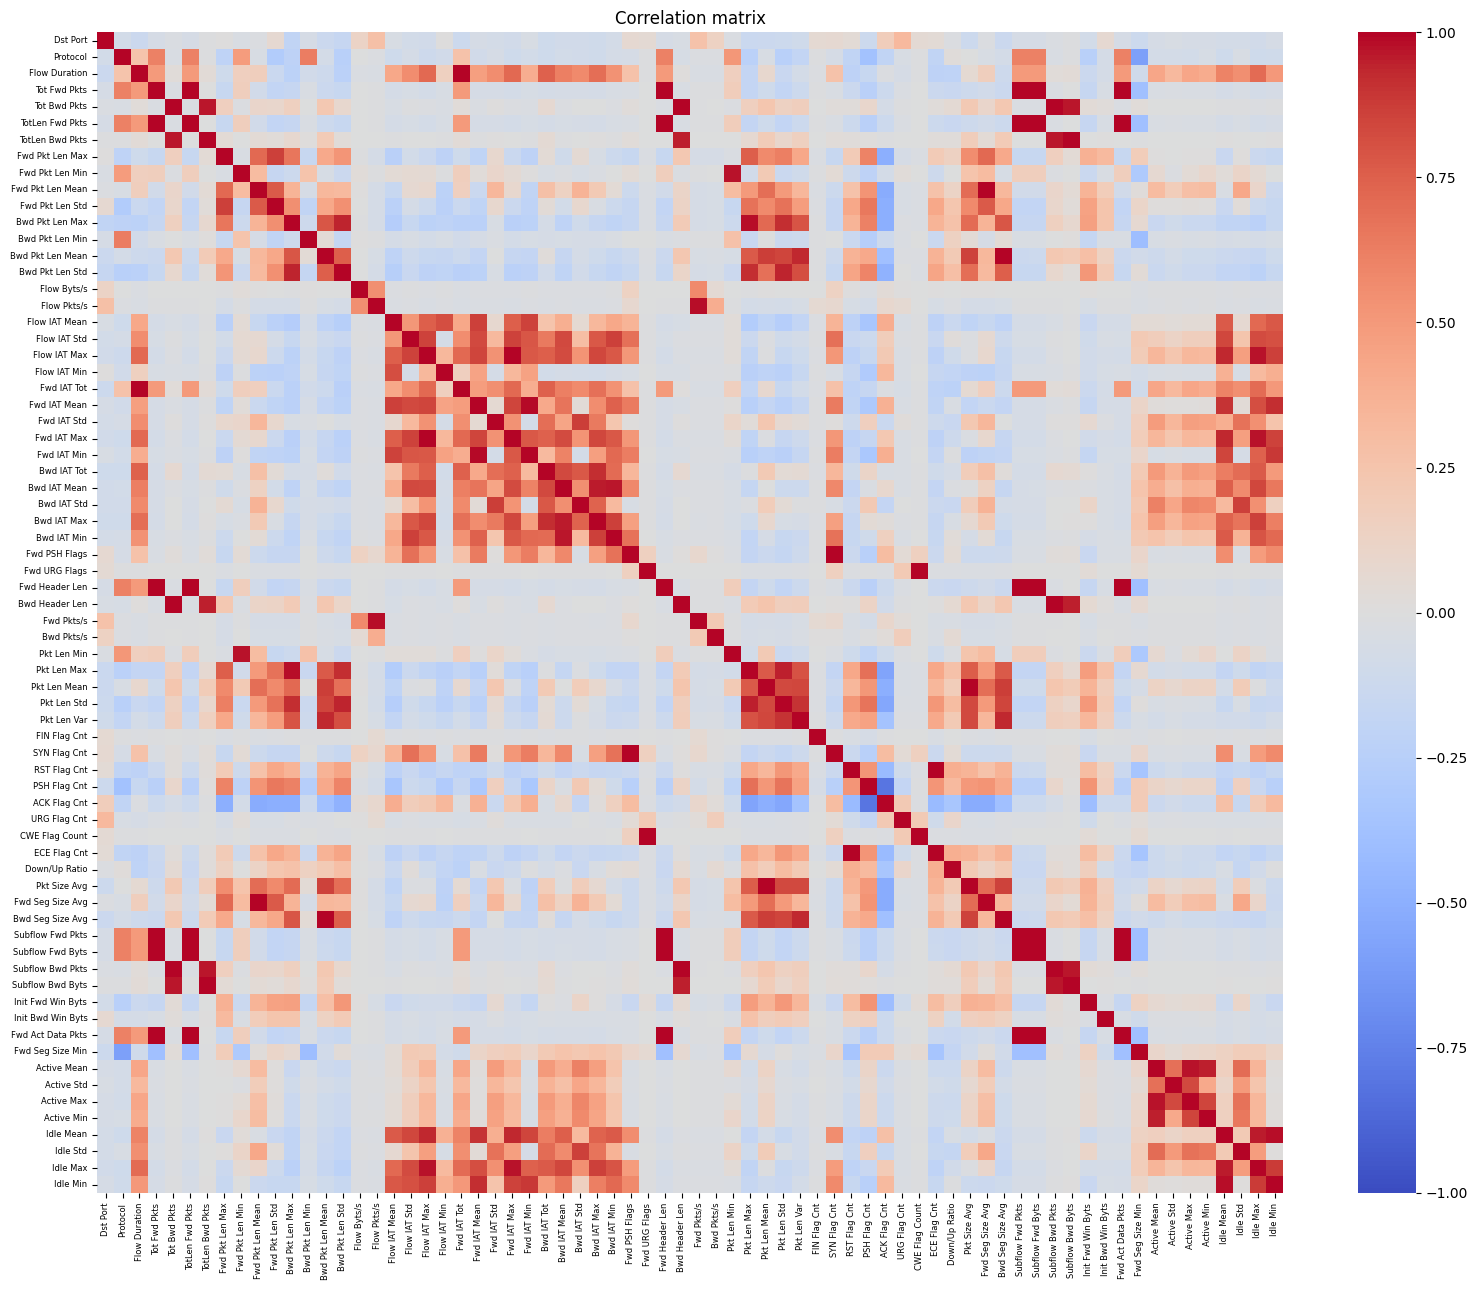

In [12]:
corr = plot_df[feature_cols].corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, xticklabels=True, yticklabels=True)
plt.xticks(fontsize=6)
plt.yticks(fontsize=6)
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_correlation.png", dpi=150)
plt.show()

In [13]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = pairs[pairs.abs() > 0.95].sort_values(key=abs, ascending=False)

print(f"Pairs with |r| > 0.95: {len(pairs)}")
pairs.head(15).round(3).to_frame("r")

Pairs with |r| > 0.95: 42


,,r
Tot Bwd Pkts,Subflow Bwd Pkts,1.0
Tot Fwd Pkts,Subflow Fwd Pkts,1.0
Bwd Pkt Len Mean,Bwd Seg Size Avg,1.0
Fwd PSH Flags,SYN Flag Cnt,1.0
RST Flag Cnt,ECE Flag Cnt,1.0
Fwd URG Flags,CWE Flag Count,1.0
TotLen Bwd Pkts,Subflow Bwd Byts,1.0
Fwd Pkt Len Mean,Fwd Seg Size Avg,1.0
TotLen Fwd Pkts,Subflow Fwd Byts,1.0
Tot Fwd Pkts,Fwd Act Data Pkts,1.0


## 6. Destination ports and protocols
The destination port shows which **service** is targeted (21 FTP, 22 SSH, 80 HTTP, 443 HTTPS, 3389 RDP...).
These are the services of the bank network designed in Partie 1.

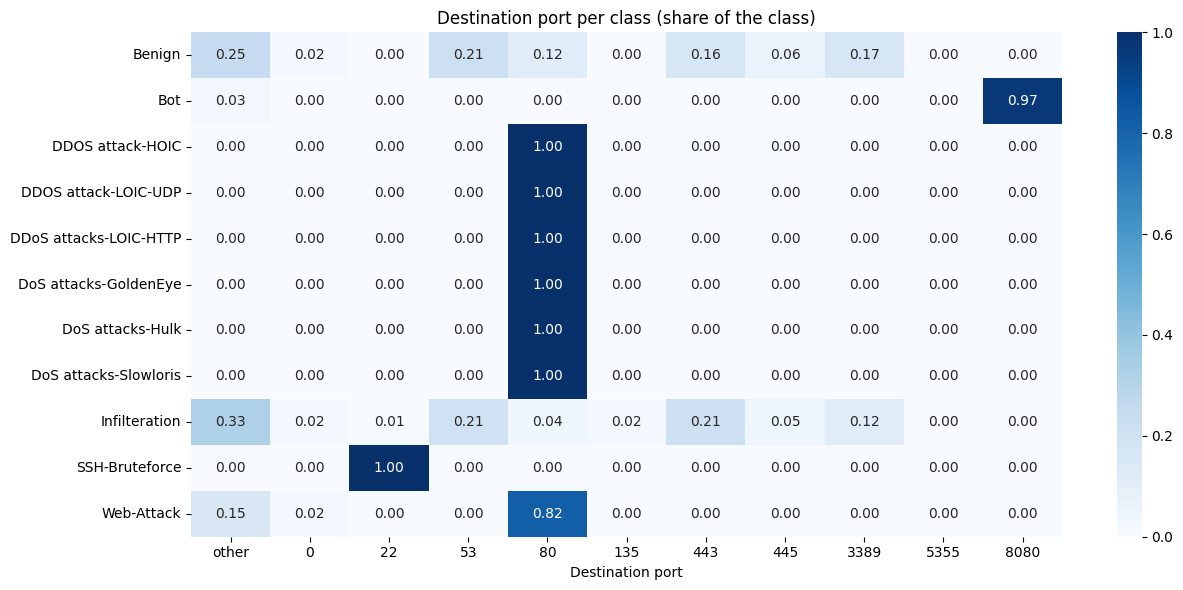

In [14]:
top_ports = df["Dst Port"].value_counts().head(10).index
ports = df["Dst Port"].where(df["Dst Port"].isin(top_ports), -1).astype(int)

table = pd.crosstab(df["Label"], ports, normalize="index")
table = table.rename(columns={-1: "other"})

plt.figure(figsize=(13, 6))
sns.heatmap(table, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Destination port per class (share of the class)")
plt.xlabel("Destination port")
plt.ylabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_ports.png", dpi=150)
plt.show()

In [15]:
protocol = df["Protocol"].map({0: "Other (0)", 6: "TCP (6)", 17: "UDP (17)"})
pd.crosstab(df["Label"], protocol, normalize="index").round(3)

Protocol,Other (0),TCP (6),UDP (17)
Label,,,
Benign,0.021,0.757,0.223
Bot,0.002,0.998,0.000
DDOS attack-HOIC,0.000,1.000,0.000
DDOS attack-LOIC-UDP,0.000,0.000,1.000
DDoS attacks-LOIC-HTTP,0.000,0.999,0.001
DoS attacks-GoldenEye,0.000,1.000,0.000
DoS attacks-Hulk,0.000,1.000,0.000
DoS attacks-Slowloris,0.000,1.000,0.000
Infilteration,0.020,0.767,0.213


## 7. Which features separate the classes best?
**Mutual information** measures how much a feature tells us about the label (0 = nothing).
Unlike correlation, it also captures non-linear relations. (Takes a few minutes.)

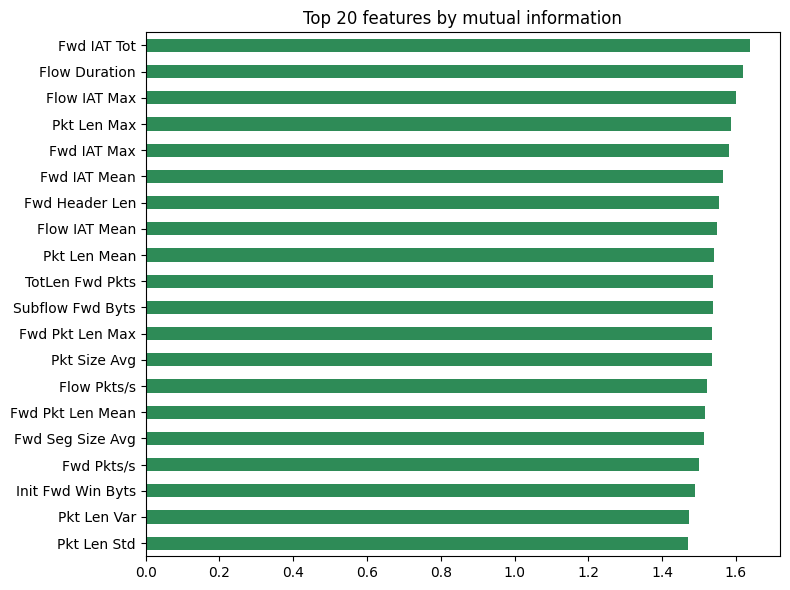

In [16]:
from sklearn.feature_selection import mutual_info_classif

mi = mutual_info_classif(plot_df[feature_cols], plot_df["Label"], random_state=SEED)
mi = pd.Series(mi, index=feature_cols).sort_values()

ax = mi.tail(20).plot(kind="barh", figsize=(8, 6), color="seagreen")
ax.set_title("Top 20 features by mutual information")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_mutual_information.png", dpi=150)
plt.show()

## 8. PCA projection
Projects all features onto 2 dimensions to see which classes **overlap**. Overlapping classes will probably be
confused by the models too. PCA is linear, so overlap here doesn't mean the classes can't be separated.

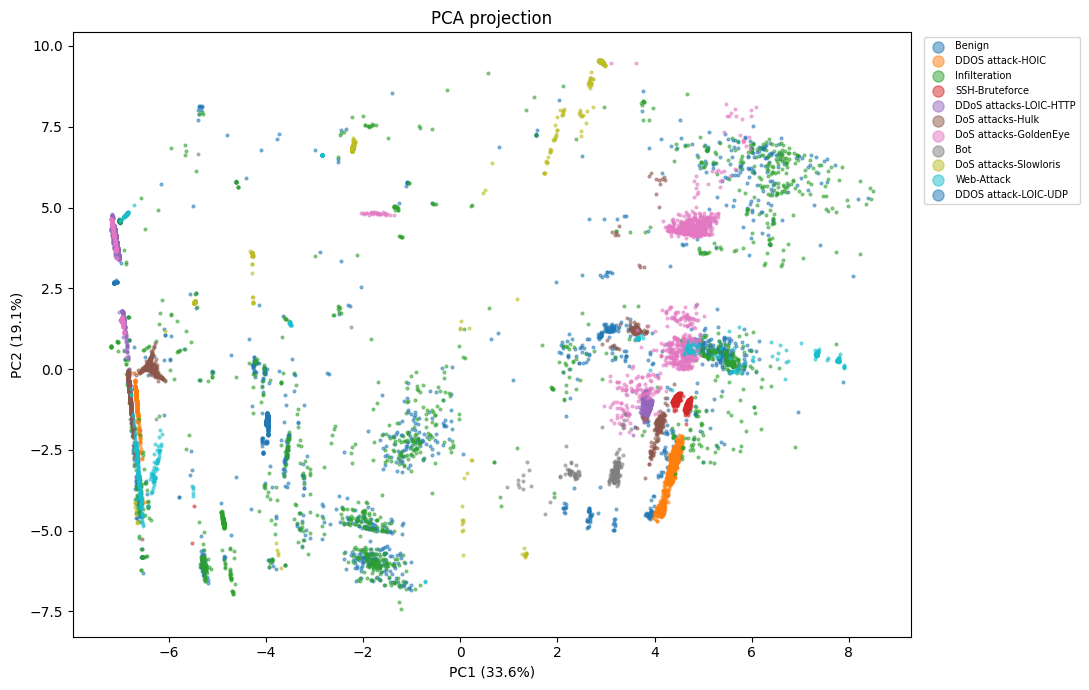

In [17]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pca_df = plot_df.groupby("Label").head(1500)
X_pca = StandardScaler().fit_transform(np.log1p(pca_df[feature_cols].clip(lower=0)))
pca = PCA(n_components=2, random_state=SEED)
P = pca.fit_transform(X_pca)

plt.figure(figsize=(11, 7))
for label in pca_df["Label"].unique():
    m = (pca_df["Label"] == label).to_numpy()
    plt.scatter(P[m, 0], P[m, 1], s=4, alpha=0.5, label=label)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.legend(markerscale=4, fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.title("PCA projection")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_pca.png", dpi=150)
plt.show()

## 9. Key takeaways
- **Imbalance:** ratio **1,931 : 1** (Benign with 1,643,296 flows vs Web-Attack with 851 flows) → class weights and macro-F1
- **Skewed features:** **29** features with |skewness| > 10 → log transform before scaling
- **Redundancy:** **42** pairs with |r| > 0.95 → remove highly correlated features in notebook 05
- **Ports:** each attack targets specific services (e.g., **SSH-Bruteforce** on port 22, **Botnet** on port 8080, **LOIC/HOIC/Hulk/GoldenEye/Slowloris** on port 80/HTTP, **Web-Attack** on port 80) → link with the ACLs of Partie 1
- **Most informative features:** **Fwd IAT Tot, Flow Duration, Flow IAT Max, Pkt Len Max, Fwd IAT Max** (from mutual information analysis)
- **Classes that overlap (PCA):** Highly overlapping regions exist between **Benign, Infiltration, and Web-Attack** on the right side of the PC projection space, which might be harder for linear models to separate.